# Встреча 5. Где обычный A/B ломается

Обычный A/B держится на трёх допущениях: единицы независимы, назначение случайно, исход единицы зависит только от её собственного назначения (SUTVA). В оффлайне, на маркетплейсах и в логистике ломается хотя бы одно. Разберём, что именно ломается и какой дизайн это чинит.

**Легенда.** Сеть из 300 магазинов у дома: 6 регионов, 3 формата, недельная выручка и трафик с января 2024 года по июнь 2025-го. Осенью 2024 года сеть открыла бьюти-зону с консультантом. Рандомизации не было: директор по рознице сам выбрал 60 «сильных» магазинов. Зона работала 12 недель, с 7 октября по 29 декабря 2024 года.

Директор принёс отчёт: «Выручка выросла почти на 6% относительно остальной сети, интервал далеко от нуля». Зона окупается, если выручка растёт хотя бы на **4.5%** (допущение легенды: аренда места, консультант, товарный запас). Нужны честная оценка эффекта и ответ, окупается ли зона. В конце — другая гипотеза сети, про доставку из магазинов, где ломается уже SUTVA.

Материал опирается на лекции и практику курса Hypothesis-Testing-Course о кластерных A/B, тестах в оффлайне и switchback, а также на работы Bertrand, Duflo, Mullainathan (2004) о DiD, Abadie и др. (2010) о синтетическом контроле и Bojinov и др. (2023) о switchback.

**Разделы**

1. Единица анализа: ICC и дизайн-эффект.
2. Пилот в оффлайне: мощность, DiD и пары.
3. Пилот директора: наивный DiD и плацебо по датам.
4. Пары, поправка на тренд и решение.
5. Что ещё видно в пилоте: трафик и чек, синтетический контроль, вторая волна.
6. Интерференция и switchback.
7. Итог: карта «ограничение → дизайн».

По ходу встречаются вопросы для обсуждения: сначала подумайте и обсудите, потом раскройте ответ.

### Библиотеки и данные

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from scipy.optimize import nnls
from scipy.signal import lfilter

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data/store_panel.csv')

SEED = 2027
ALPHA, POWER = 0.05, 0.80
Z = stats.norm.ppf(1 - ALPHA / 2)                 # ≈ 1.96
Z_SUM = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)   # ≈ 2.80
PRE, POST = 12, 12                  # недель до пилота и недель пилота
PILOT_START = pd.Timestamp('2024-10-07')
BREAKEVEN = 0.045                   # допущение легенды: зона окупается при +4.5% выручки

Панель «магазин × неделя». Список магазинов директора — из его же отчёта; в данных пометки нет.

In [2]:
panel = pd.read_csv(DATA, parse_dates=['week'])
PILOT_STORES = [4, 7, 16, 26, 31, 43, 48, 49, 55, 56, 71, 76, 78, 86, 88, 91, 93, 96, 100, 101, 102, 105, 108, 114, 123, 133, 134, 144, 151, 155, 164, 165, 166, 167, 171, 192, 194, 204, 212, 214, 215, 216, 218, 221, 230, 236, 238, 241, 244, 247, 251, 254, 256, 263, 266, 271, 283, 285, 290, 299]

sales = panel.pivot(index='week', columns='store', values='sales')
Y = np.log(sales).to_numpy()                         # недели × магазины, лог выручки
WEEKS, STORES = sales.index, sales.columns.to_numpy()
N_WEEKS, N_STORES = Y.shape
T0 = WEEKS.get_loc(PILOT_START)                      # индекс первой недели пилота
HIST = Y[:T0]                                        # история до пилота: здесь эффекта нет ни у кого

info = panel.drop_duplicates('store').set_index('store').loc[STORES, ['region', 'format']]
is_pilot = np.isin(STORES, PILOT_STORES)
pilot_idx, rest_idx = np.where(is_pilot)[0], np.where(~is_pilot)[0]

print(f"Магазинов: {N_STORES}, недель: {N_WEEKS}, пилот с недели {T0} ({PILOT_START:%d.%m.%Y}), до пилота {T0} недель")
print(f"Пилот: {len(pilot_idx)} магазинов, остальная сеть: {len(rest_idx)}")
print('Форматы, доля в пилоте и в сети:')
print(pd.DataFrame({'пилот': info[is_pilot]['format'].value_counts(normalize=True),
                    'сеть': info['format'].value_counts(normalize=True)}).round(2).to_string())
panel.head()

Магазинов: 300, недель: 78, пилот с недели 40 (07.10.2024), до пилота 40 недель
Пилот: 60 магазинов, остальная сеть: 240
Форматы, доля в пилоте и в сети:
        пилот  сеть
format             
a        0.63  0.48
b        0.35  0.37
c        0.02  0.15


,store,region,format,week,sales,traffic,promo
0,1,ПФО,b,2024-01-01,1515524.37,1331,0
1,2,УФО,b,2024-01-01,1628195.51,1307,1
2,3,СФО,a,2024-01-01,1155332.87,955,0
3,4,ПФО,a,2024-01-01,1754470.26,1597,0
4,5,ЦФО,a,2024-01-01,1541252.69,777,0


Анализируем **логарифм** недельной выручки: разность логарифмов — почти процентное изменение, а магазины разного размера становятся сравнимы. Эффект в логах $\tau$ переводится в проценты как $e^\tau - 1$; при 4.5% это $\ln 1.045 = 0.044$.

## 1. Единица анализа: ICC и дизайн-эффект

Если воздействие назначено магазину, то 12 недель одного магазина — не 12 наблюдений. Они делят общий уровень магазина: размер, локацию, трафик. Сколько в них независимой информации, говорит ICC.

Модель: недельная метрика магазина $j$ в неделю $i$

$$
Y_{ij} = \mu + u_j + e_{ij}
$$

$$
\rho = \text{ICC} = \frac{\sigma_u^2}{\sigma_u^2 + \sigma_e^2}
$$

$\rho$ — доля дисперсии, которая приходится на различия **между** магазинами, и одновременно корреляция двух недель одного магазина. Среднее по $m$ неделям магазина имеет дисперсию $\frac{\sigma^2}{m} (1 + (m-1)\rho)$. Множитель

$$
DE = 1 + (m - 1) \rho
$$

— **дизайн-эффект**: во столько раз реальная дисперсия больше той, что считает тест «строки независимы». Эффективный размер выборки — $n / DE$.

Посмотрим, каков ICC в нашей сети (лог недельной выручки, 40 недель до пилота).

In [3]:
def icc(matrix: np.ndarray) -> float:
    # Доля дисперсии между магазинами; matrix — недели × магазины
    between = matrix.mean(axis=0).var()
    within = (matrix - matrix.mean(axis=0)).var()
    return between / (between + within)


rho = icc(HIST)
design_effect = 1 + (POST - 1) * rho
print(f"Дисперсия между магазинами {HIST.mean(axis=0).var():.4f}, внутри магазина {(HIST - HIST.mean(axis=0)).var():.4f}")
print(f"ICC = {rho:.2f}; для {POST} недель DE = {design_effect:.1f}: "
      f"300 магазинов × 12 недель = 3 600 строк ≈ {3600 / design_effect:.0f} независимых")

Дисперсия между магазинами 0.1431, внутри магазина 0.0096
ICC = 0.94; для 12 недель DE = 11.3: 300 магазинов × 12 недель = 3 600 строк ≈ 318 независимых


**ICC 0.94.** Дисперсия между магазинами в 15 раз больше, чем внутри магазина: 0.143 против 0.0096. При 12 неделях $DE = 11.3$: 3 600 магазино-недель весят как ~320 независимых наблюдений, почти одно на магазин.

Что будет, если этого не заметить и сделать t-тест по строкам? Тест занижает дисперсию в $DE$ раз, поэтому на A/A срабатывает с вероятностью

$$
2 \Phi(-z_{1-\alpha/2} / \sqrt{DE})
$$

вместо 5%.

**Вопрос.** ICC 0.94 — крайний случай. А если ICC всего 0.01, можно ли спокойно считать наблюдения независимыми?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет, если наблюдений в кластере много. Дизайн-эффект $1 + (m-1)\rho$ растёт с $m$: при ICC 0.01 и 52 наблюдениях в кластере $DE \approx 1.5$, и наивный тест срабатывает на A/A примерно в 11% случаев вместо 5%. Для пользовательских кластеров (город, класс, чат) с тысячами пользователей даже ICC 0.001 даёт заметный DE.

Маленький ICC безопасен, только когда маленькое и произведение $(m-1)\rho$.

</details>

Проверим формулу симуляцией: 40 кластеров, две половины, эффекта нет. Справа — MDE при 40 кластерах на группу в зависимости от числа наблюдений в кластере.

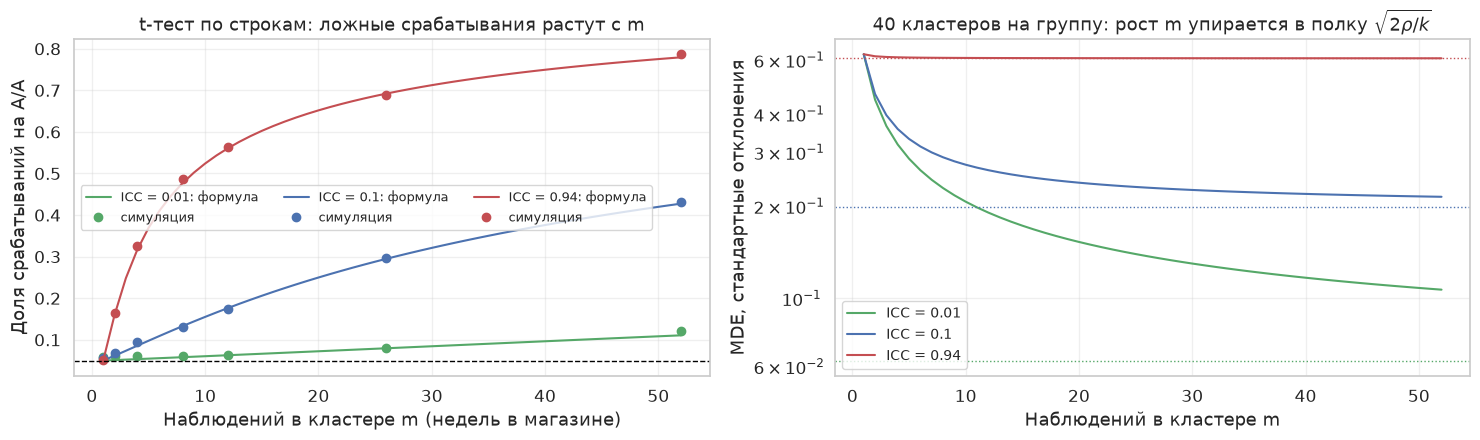

ICC 0.94, 12 недель: формула 56%, симуляция 56%
ICC 0.01, 52 наблюдения: формула 11%


In [4]:
def naive_fpr_sim(rho: float, m: int, k: int = 40, reps: int = 4000, seed: int = 1) -> float:
    # A/A: k кластеров по m наблюдений, t-тест по наблюдениям, будто они независимы
    rng = np.random.default_rng(seed)
    u = rng.normal(0, np.sqrt(rho), (reps, k, 1))
    e = rng.normal(0, np.sqrt(1 - rho), (reps, k, m))
    y = (u + e).reshape(reps, k, m)
    a, b = y[:, :k // 2].reshape(reps, -1), y[:, k // 2:].reshape(reps, -1)
    t = (a.mean(1) - b.mean(1)) / np.sqrt(a.var(1, ddof=1) / a.shape[1] + b.var(1, ddof=1) / b.shape[1])
    return np.mean(np.abs(t) > Z)


def naive_fpr_formula(rho, m):
    return 2 * stats.norm.sf(Z / np.sqrt(1 + (np.asarray(m) - 1) * rho))


def cluster_mde(k, m, rho, power=0.8):
    # MDE в стандартных отклонениях: k кластеров на группу по m наблюдений
    return (Z + stats.norm.ppf(power)) * np.sqrt(2 * (1 + (np.asarray(m) - 1) * rho) / (k * np.asarray(m)))


ms = np.array([1, 2, 4, 8, 12, 26, 52])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for r, color in [(0.01, GREEN), (0.1, BLUE), (round(rho, 2), RED)]:
    grid = np.arange(1, 53)
    axes[0].plot(grid, naive_fpr_formula(r, grid), color=color, label=f'ICC = {r}: формула')
    axes[0].plot(ms, [naive_fpr_sim(r, m) for m in ms], 'o', color=color, label='симуляция')
    axes[1].plot(grid, cluster_mde(40, grid, r), color=color, label=f'ICC = {r}')
    axes[1].axhline(cluster_mde(40, 1e9, r), color=color, linestyle=':', linewidth=1)
axes[0].axhline(ALPHA, color='black', linestyle='--', linewidth=1)
axes[0].set(xlabel='Наблюдений в кластере m (недель в магазине)', ylabel='Доля срабатываний на A/A',
            title='t-тест по строкам: ложные срабатывания растут с m')
axes[0].legend(fontsize=9, ncol=3)
axes[1].set(xlabel='Наблюдений в кластере m', ylabel='MDE, стандартные отклонения', yscale='log',
            title='40 кластеров на группу: рост m упирается в полку $\\sqrt{2\\rho/k}$')
axes[1].legend(fontsize=10)
plt.tight_layout(); plt.show()
print(f"ICC {rho:.2f}, 12 недель: формула {naive_fpr_formula(rho, 12):.0%}, симуляция {naive_fpr_sim(rho, 12):.0%}")
print(f"ICC 0.01, 52 наблюдения: формула {naive_fpr_formula(0.01, 52):.0%}")

Формула совпала с симуляцией: при ICC 0.94 и 12 неделях наивный тест срабатывает в **56%** A/A. Справа видно, что при большом ICC MDE с первых же недель упирается в полку, пропорциональную $\sqrt{2\rho/k}$.

Теперь то же на истории нашей сети. A/A-тест: случайная дата старта до пилота, две случайные половины сети, никакого воздействия. Сравним четыре анализа:

* t-тест по магазино-неделям — каждое значение за 12 недель как отдельное наблюдение;
* t-тест по магазинам — одно число на магазин, среднее за 12 недель;
* DiD по магазино-неделям с ошибкой «как будто строки независимы»;
* DiD по магазинам — одно изменение на магазин: среднее за 12 недель минус среднее за 12 недель до них.

Правильный тест срабатывает в 5% случаев.

In [5]:
def aa_pvalue(level: str, t0: int, a: np.ndarray, b: np.ndarray) -> float:
    post = HIST[t0:t0 + POST]
    if level == 'магазино-неделя':
        x, y = post[:, a].ravel(), post[:, b].ravel()
    elif level == 'магазин':
        x, y = post[:, a].mean(axis=0), post[:, b].mean(axis=0)
    else:
        raise ValueError(level)
    return stats.ttest_ind(x, y).pvalue


def random_window(rng, post: int = POST, pre: int = PRE) -> int:
    # Случайная дата старта псевдопилота так, чтобы до и после поместились в историю
    return int(rng.integers(pre, T0 - post + 1))


def did_rows_pvalue(t0, a, b):
    # DiD по магазино-неделям с ошибкой, будто все строки независимы
    m = HIST[t0 - PRE:t0 + POST][:, np.r_[a, b]]
    m = m - m.mean(axis=0, keepdims=True) - m.mean(axis=1, keepdims=True) + m.mean()
    k = len(a)
    effect = m[PRE:, :k].mean() - m[PRE:, k:].mean() - m[:PRE, :k].mean() + m[:PRE, k:].mean()
    se = m.std() * np.sqrt(2 / (POST * k) + 2 / (PRE * k))
    return 2 * stats.norm.sf(abs(effect / se))


def did_stores_pvalue(t0, a, b):
    delta = HIST[t0:t0 + POST].mean(axis=0) - HIST[t0 - PRE:t0].mean(axis=0)
    return stats.ttest_ind(delta[a], delta[b]).pvalue


def aa_fpr(R: int = 600, seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)
    hits = {'t-тест по магазино-неделям': 0, 'DiD по магазино-неделям': 0, 't-тест по магазинам': 0, 'DiD по магазинам': 0}
    for _ in range(R):
        t0 = random_window(rng)
        order = rng.permutation(N_STORES)
        a, b = order[:N_STORES // 2], order[N_STORES // 2:]
        hits['t-тест по магазино-неделям'] += aa_pvalue('магазино-неделя', t0, a, b) < ALPHA
        hits['t-тест по магазинам'] += aa_pvalue('магазин', t0, a, b) < ALPHA
        hits['DiD по магазино-неделям'] += did_rows_pvalue(t0, a, b) < ALPHA
        hits['DiD по магазинам'] += did_stores_pvalue(t0, a, b) < ALPHA
    return pd.Series(hits) / R


fpr = aa_fpr()
print(fpr.map('{:.1%}'.format).to_string())

t-тест по магазино-неделям    57.7%
DiD по магазино-неделям        8.3%
t-тест по магазинам            4.5%
DiD по магазинам               5.8%


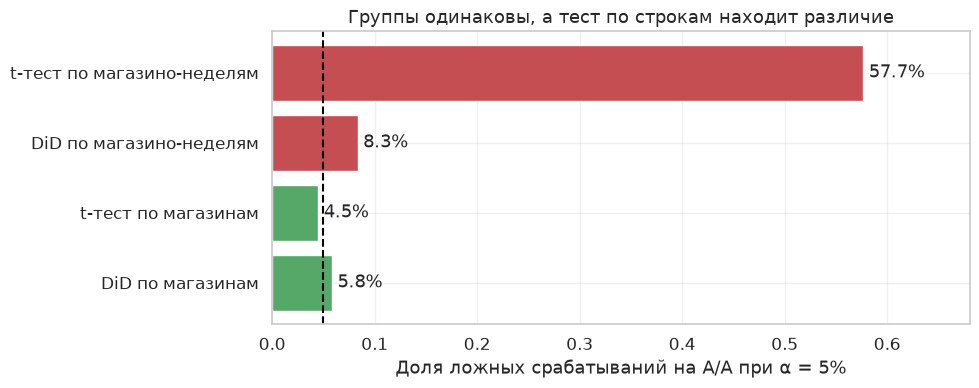

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = [RED if v > 0.07 else (ORANGE if v > 0.06 else GREEN) for v in fpr.values[::-1]]
bars = ax.barh(fpr.index[::-1], fpr.values[::-1], color=colors)
ax.bar_label(bars, labels=[f"{v:.1%}" for v in fpr.values[::-1]], padding=4)
ax.axvline(ALPHA, color='black', linestyle='--')
ax.set_xlim(0, fpr.max() * 1.18); ax.set_xlabel('Доля ложных срабатываний на A/A при α = 5%')
ax.set_title('Группы одинаковы, а тест по строкам находит различие')
plt.show()

Группы одинаковы по построению, а t-тест по магазино-неделям находит различие в **58%** A/A — формула дизайн-эффекта предсказала 56%. Тесты по магазинам держат уровень: 4.5% и 5.8% (при 600 прогонах шум ±1.8 п.п.). DiD по магазино-неделям с ошибкой «строки независимы» — **8.3%**.

**Вопрос.** Почему DiD по магазино-неделям ошибается гораздо меньше, чем t-тест по ним же, но всё же больше 5%? Где он сломался бы сильнее?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

DiD вычитает уровень магазина, а именно он даёт ICC 0.94. После вычитания остаются недельный шум и тренды магазинов. Недельный шум в этой синтетической сети почти независим, поэтому формула «строки независимы» ошибается мало. Перекос даёт только то, что часть магазинов растёт быстрее остальных: это медленная компонента, она одинакова для всех недель магазина.

В реальных сетях недели одного магазина автокоррелированы: ремонт, конкурент открылся рядом, сменился директор. Там DiD по строкам срабатывает на A/A намного чаще 5% (Bertrand, Duflo, Mullainathan, 2004).

</details>

Рецепт одинаковый:

* **единица анализа = единица рандомизации** — одно число на магазин (среднее или изменение), тест по магазинам;
* или кластеризованные ошибки по магазину; при малом числе кластеров — рандомизационный тест.

## 2. Пилот в оффлайне: мощность, DiD и пары

Магазинов мало, они разные, а список пилотных часто составляет бизнес. Поэтому основная работа делается до старта:

1. **Отбор пула** — только магазины, где изменение физически возможно и данные полные (без закрытий и ремонтов).
2. **Пары** — похожие магазины объединяем в пары, внутри пары монеткой выбираем пилотный. Пары страхуют от неудачного разбиения и дают понятный анализ.
3. **Мощность инъекцией** — вместо формулы: берём историю, случайные окна и группы, считаем оценку; её разброс даёт MDE; добавляем известный эффект и смотрим, как часто метод его находит.
4. **DiD** — сравниваем не уровни, а изменения: $\Delta_i = \bar y_i^{\text{после}} - \bar y_i^{\text{до}}$. Магазин — сам себе контроль, постоянные различия вычитаются.
5. **Плацебо по датам** — тот же расчёт на окнах до старта. Если «эффект» есть там, где воздействия не было, — метод смещён.

DiD держится на **параллельных трендах**: без пилота группы менялись бы одинаково. Случайное назначение это гарантирует в среднем, выбор бизнеса — нет.

### Мощность инъекцией эффекта

Формула MDE из встречи 2 считает наблюдения независимыми, а у нас они зависимы, и шум магазина устроен сложнее. Поэтому мощность считаем прямо по истории:

1. берём случайное окно и случайные группы магазинов, считаем DiD: $\Delta_i$ — изменение магазина, оценка — разность средних $\Delta_i$ двух групп;
2. стандартное отклонение оценки по прогонам $\sigma_{DiD}$ даёт MDE:

$$
MDE = (z_{1-\alpha/2} + z_{1-\beta}) \sigma_{DiD}
$$

3. для проверки **впрыскиваем** эффект в пилотную группу и смотрим, как часто t-тест по магазинам его находит.

In [7]:
def _did_deltas(rng, n_t, n_c, post):
    t0 = random_window(rng, post=post)
    idx = rng.choice(N_STORES, n_t + n_c, replace=False)
    delta = HIST[t0:t0 + post, idx].mean(axis=0) - HIST[t0 - PRE:t0, idx].mean(axis=0)
    return delta[:n_t], delta[n_t:]


def did_sd(n_t: int, n_c: int, post: int = POST, R: int = 600, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    effects = []
    for _ in range(R):
        a, b = _did_deltas(rng, n_t, n_c, post)
        effects.append(a.mean() - b.mean())
    return float(np.std(effects))


def injected_power(lift: float, n_t: int, n_c: int, post: int = POST, R: int = 600, seed: int = SEED) -> float:
    rng = np.random.default_rng(seed)
    hits = 0
    for _ in range(R):
        a, b = _did_deltas(rng, n_t, n_c, post)
        hits += stats.ttest_ind(a + lift, b).pvalue < ALPHA
    return hits / R

In [8]:
sd_40 = did_sd(40, 40)
power_0 = injected_power(0.0, 40, 40)
power_mde = injected_power(Z_SUM * sd_40, 40, 40)
print(f"40 + 40, 12 недель: σ_DiD = {sd_40:.2%}, MDE = {Z_SUM * sd_40:.2%}; A/A {power_0:.3f}, мощность на MDE {power_mde:.3f}")

40 + 40, 12 недель: σ_DiD = 0.48%, MDE = 1.34%; A/A 0.062, мощность на MDE 0.817


Для 40 + 40 магазинов и 12 недель MDE 1.34%: без эффекта тест срабатывает в 6% прогонов (шум ±1.8 п.п.), на MDE — в 82%. Метод сходится с определением мощности.

**Вопрос.** Пилот на 40 + 40 магазинов и 8 недель. Что сильнее снизит MDE: вдвое больше магазинов или пилот на 50% длиннее (12 недель)?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Магазины. Удвоение группы с 40 до 80 магазинов при 8 неделях снижает MDE с 1.45% до 1.05%. Удлинение пилота с 8 до 12 недель — только с 1.45% до 1.34%.

После 8 недель MDE почти на полке. Предпериод фиксирован (12 недель), его шум не усредняется. А у части магазинов свой тренд — медленная компонента, которая не усредняется, сколько ни жди. Это та же полка из раздела 1: недели её не сдвигают, сдвигает только число магазинов $k$.

Оговорка: в нашей синтетике недельный шум независим, поэтому недели помогают дольше обычного. Если у магазинов сильнее медленный дрейф (ремонт, конкурент рядом, смена директора), полка наступает раньше. Такой расчёт делают заново на истории своей сети.

</details>

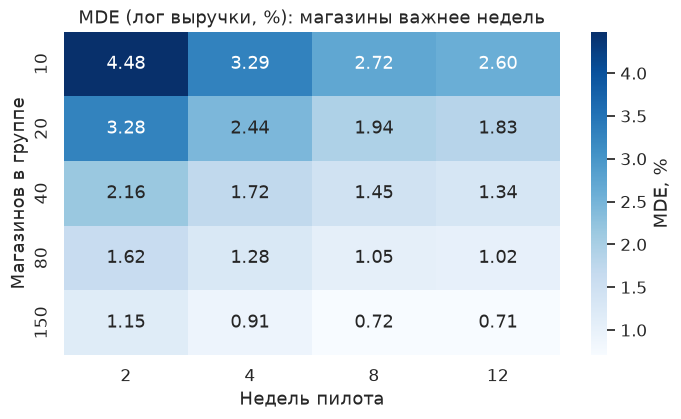

Недель пилота         2     4     8     12
Магазинов в группе                        
10                  4.48  3.29  2.72  2.60
20                  3.28  2.44  1.94  1.83
40                  2.16  1.72  1.45  1.34
80                  1.62  1.28  1.05  1.02
150                 1.15  0.91  0.72  0.71
Дизайн директора, 60 против 240, 12 недель: σ_DiD = 0.30%, MDE = 0.85%


In [9]:
ks, posts = (10, 20, 40, 80, 150), (2, 4, 8, 12)
mde = pd.DataFrame({post: {k: 100 * Z_SUM * did_sd(k, k, post) for k in ks} for post in posts})
mde.index.name, mde.columns.name = 'Магазинов в группе', 'Недель пилота'
sd_director = did_sd(60, 240)
mde_director = Z_SUM * sd_director

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(mde, annot=True, fmt='.2f', cmap='Blues', cbar_kws={'label': 'MDE, %'}, ax=ax)
ax.set_title('MDE (лог выручки, %): магазины важнее недель')
plt.show()
print(mde.round(2).to_string())
print(f"Дизайн директора, 60 против 240, 12 недель: σ_DiD = {sd_director:.2%}, MDE = {mde_director:.2%}")

Дизайн директора — 60 магазинов против 240 за 12 недель: **MDE 0.85%**. Эффект в 4.5% он увидел бы с большим запасом.

**Вопрос.** Мощности у пилота директора хватает с запасом. Значит ли это, что его оценке можно верить?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Мощность и интервал описывают только **случайный** разброс: что будет, если выбирать магазины и даты случайно. Директор выбирал не случайно. Если отбор связан с динамикой выручки, оценка смещена, и смещение не уменьшается ни от числа магазинов, ни от длины пилота.

Ниже это видно на симуляции, а в разделе 3 — на данных сети.

</details>

### Что дают DiD, пары и выбор бизнеса

Симуляция: 200 магазинов, у каждого свой уровень и свой небольшой тренд, 40 недель истории. Пилот — 30 магазинов, 12 недель, эффект +3%. Сравним четыре способа: случайно + разность уровней, случайно + DiD, пары + DiD и «бизнес выбрал растущие» + DiD, а для последнего — плацебо на окне до старта.

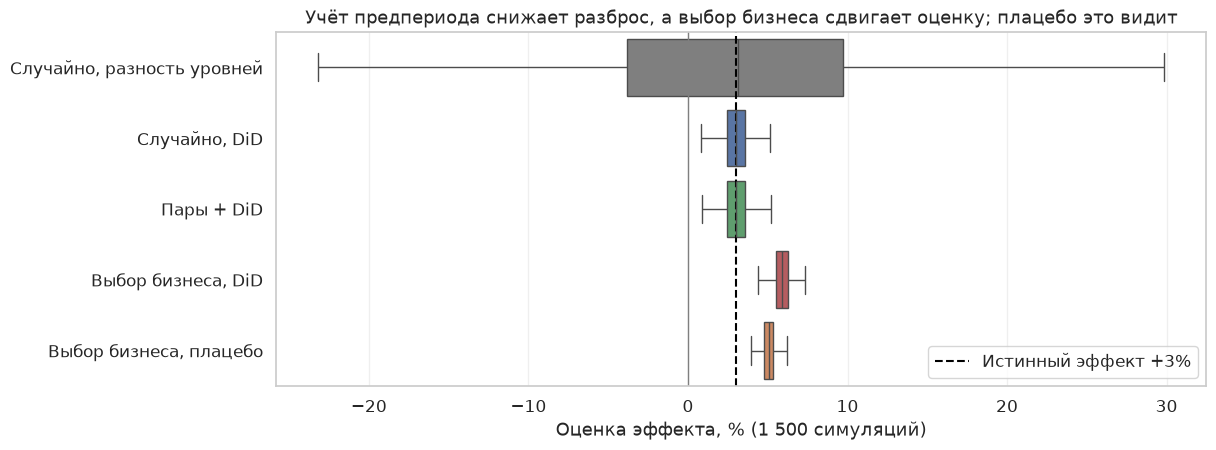

,"Среднее, %","Разброс, %"
"Случайно, разность уровней",2.97,10.29
"Случайно, DiD",2.99,0.81
Пары + DiD,3.03,0.83
"Выбор бизнеса, DiD",5.88,0.56
"Выбор бизнеса, плацебо",5.06,0.43


In [10]:
def toy_panel(rng, n=200, weeks=40):
    level = rng.normal(0, 0.4, n)
    slope = rng.normal(0, 0.002, n)                   # у магазинов свои тренды
    t = np.arange(weeks)[:, None]
    return level + slope * t + rng.normal(0, 0.05, (weeks, n)), slope


def pilot_estimates(reps=1500, k=30, effect=0.03, t0=28, pre=12, post=12, seed=3):
    rng = np.random.default_rng(seed)
    out = {name: [] for name in ['Случайно, разность уровней', 'Случайно, DiD', 'Пары + DiD',
                                 'Выбор бизнеса, DiD', 'Выбор бизнеса, плацебо']}
    for _ in range(reps):
        y, slope = toy_panel(rng)
        n = y.shape[1]
        delta = lambda m, s: m[s:s + post].mean(0) - m[s - pre:s].mean(0)

        def did(treated, start, lift):
            m = y.copy(); m[start:start + post, treated] += lift
            d = delta(m, start); mask = np.zeros(n, bool); mask[treated] = True
            return d[mask].mean() - d[~mask].mean()

        # случайно: 2k магазинов, половина в пилот (столько же, сколько в парах)
        sample = rng.choice(n, 2 * k, replace=False)
        tr, ct = sample[:k], sample[k:]
        m = y.copy(); m[t0:t0 + post, tr] += effect
        out['Случайно, разность уровней'].append(m[t0:t0 + post, tr].mean() - m[t0:t0 + post, ct].mean())
        d = delta(m, t0)
        out['Случайно, DiD'].append(d[tr].mean() - d[ct].mean())
        # пары по уровню до старта: соседей по уровню объединяем, монетка внутри пары
        order = np.argsort(y[t0 - pre:t0].mean(0))
        pairs = order.reshape(-1, 2)[rng.choice(n // 2, k, replace=False)]
        coin = rng.integers(0, 2, k)
        tr, ct = pairs[np.arange(k), coin], pairs[np.arange(k), 1 - coin]
        m = y.copy(); m[t0:t0 + post, tr] += effect
        d = delta(m, t0)
        out['Пары + DiD'].append((d[tr] - d[ct]).mean())
        # бизнес выбирает магазины, которые «растут»: наибольший наклон по истории до старта
        growth = np.polyfit(np.arange(t0), y[:t0], 1)[0]
        chosen = np.argsort(-growth)[:k]
        out['Выбор бизнеса, DiD'].append(did(chosen, t0, effect))
        out['Выбор бизнеса, плацебо'].append(did(chosen, t0 - 14, 0.0))
    return pd.DataFrame(out)


est = pilot_estimates()
fig, ax = plt.subplots(figsize=(12, 4.6))
colors = [GRAY, BLUE, GREEN, RED, ORANGE]
sns.boxplot(data=est * 100, orient='h', palette=colors, ax=ax, showfliers=False)
ax.axvline(3, color='black', linestyle='--', label='Истинный эффект +3%')
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlabel('Оценка эффекта, % (1 500 симуляций)')
ax.set_title('Учёт предпериода снижает разброс, а выбор бизнеса сдвигает оценку; плацебо это видит')
ax.legend(loc='lower right')
plt.show()
table = pd.DataFrame({'Среднее, %': est.mean() * 100, 'Разброс, %': est.std() * 100}).round(2)
table

Что видно на графике:

* **Без учёта предпериода** разброс оценки 10.3%: эффект +3% тонет в различиях между магазинами.
* **DiD** снижает разброс до 0.8%, в 13 раз: уровень магазина вычитается.
* **Пары поверх DiD** почти ничего не добавляют (0.83%): они выравнивают уровень, который DiD уже убрал. Их польза в другом — страховка от неудачного разбиения при 5–10 магазинах и понятный бизнесу анализ «каждому пилотному свой контрольный».
* **Выбор бизнеса** («ставим туда, где растёт») даёт +5.9% вместо +3%. Смещение 2.9 п.п. при разбросе 0.56%: интервал уверенно не накрывает правду.
* **Плацебо** на окне до старта показывает +5.1% там, где воздействия не было. Это даже больше смещения: магазины отбирали по тем же неделям, и к тренду добавился подобранный шум. Сигнал однозначный: оценке верить нельзя. Общее правило: окно плацебо не должно пересекаться с неделями, по которым что-то подбирали (список магазинов, пары, веса). Внутри окна отбора плацебо раздуто, внутри окна подбора пар — занижено.

Что из этого следует:

* **Мощность покупается магазинами, а не неделями.** Шум магазина состоит из быстрой части, которая усредняется, и медленной (тренд, дрейф), которая не усредняется. После нескольких недель MDE почти не падает.
* **Смещение от отбора не уменьшается от роста выборки.**
* **Плацебо по датам** — обязательная проверка любого квазиэксперимента. Если оно не ноль, оценку нельзя докладывать.
* **Если отбор уже случился,** смещение от разницы в росте можно попробовать снять поправкой на тренд по истории (раздел 4).

## 3. Пилот директора: наивный DiD и плацебо по датам

**Правило решения фиксируем до того, как посмотрим на оценку.**

* Раскатываем на сеть, если нижняя граница 90%-ного интервала не ниже 4.5% и все плацебо в пределах ±1 п.п.
* Не раскатываем, если верхняя граница 90%-ного интервала ниже 4.5%.
* Всё между — серая зона: решение даёт только вторая волна со случайным выбором.
* Если плацебо не пройдены, оценку не докладываем и решение не принимаем: интервал смотрим только после плацебо.

**Вопрос.** Почему в правиле 90%-ный интервал, а не привычный 95%-ный? И зачем отдельное условие на плацебо, если интервал уже есть?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Вопрос односторонний: «окупается или нет». 90%-ный двусторонний интервал соответствует одностороннему тесту на 5%: нижняя граница отвечает на «точно выше порога?», верхняя — на «точно ниже?».

Плацебо нужно потому, что интервал не видит смещения. Он описывает только случайную ошибку, а у неслучайного отбора главная проблема — систематический сдвиг. Узкий интервал вокруг смещённой оценки выглядит убедительно и при этом неверен.

</details>

Посчитаем DiD: $\Delta_i$ — среднее лог-выручки магазина за 12 недель пилота минус среднее за 12 недель до него, эффект — разность средних $\Delta_i$ пилота и остальной сети. Тот же расчёт сделаем на четырёх **плацебо-окнах**: те же 12 + 12 недель, но целиком до старта, когда зоны не было. Если метод честный, плацебо дают около нуля.

In [11]:
def did_estimate(matrix: np.ndarray, treated: np.ndarray, control: np.ndarray, t0: int,
                 pre: int = PRE, post: int = POST) -> dict:
    delta = matrix[t0:t0 + post].mean(axis=0) - matrix[t0 - pre:t0].mean(axis=0)
    a, b = delta[treated], delta[control]
    effect = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    return {'effect': effect, 'se': se, 'low': effect - 1.96 * se, 'high': effect + 1.96 * se}


PLACEBO_T0 = [16, 20, 24, 28]        # окна до старта: последнее заканчивается за неделю до пилота
naive = did_estimate(Y, pilot_idx, rest_idx, T0)
placebo = {t: did_estimate(Y, pilot_idx, rest_idx, t) for t in PLACEBO_T0}


def fmt(est: dict) -> str:
    to_pct = lambda v: f"{np.expm1(v):+.2%}"
    return f"{to_pct(est['effect'])} [{to_pct(est['low'])}; {to_pct(est['high'])}]"


print(f"Пилот, наивный DiD: {fmt(naive)}")
for t, p in placebo.items():
    print(f"Плацебо с {WEEKS[t]:%d.%m.%Y}: {fmt(p)}")

Пилот, наивный DiD: +5.79% [+5.18%; +6.39%]
Плацебо с 22.04.2024: +2.12% [+1.55%; +2.68%]
Плацебо с 20.05.2024: +2.34% [+1.78%; +2.91%]
Плацебо с 17.06.2024: +2.34% [+1.81%; +2.87%]
Плацебо с 15.07.2024: +2.51% [+1.92%; +3.09%]


Посмотрим, почему плацебо «находит» эффект там, где зоны не было. Ниже — разность средней лог-выручки пилотных магазинов и остальной сети по неделям.

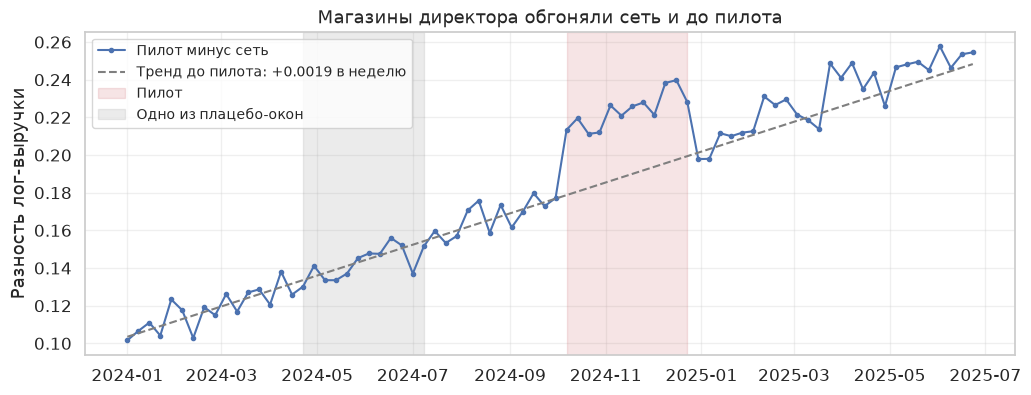

Отставание растёт на 0.0019 в неделю; между центрами окон «до» и «после» 12 недель → +0.023


In [12]:
gap = Y[:, pilot_idx].mean(axis=1) - Y[:, rest_idx].mean(axis=1)
weeks_num = np.arange(N_WEEKS)
slope, intercept = np.polyfit(weeks_num[:T0], gap[:T0], 1)

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(WEEKS, gap, color=BLUE, marker='o', markersize=3, label='Пилот минус сеть')
ax.plot(WEEKS, intercept + slope * weeks_num, color=GRAY, linestyle='--', label=f'Тренд до пилота: {slope:+.4f} в неделю')
ax.axvspan(WEEKS[T0], WEEKS[T0 + POST - 1], color=RED, alpha=0.15, label='Пилот')
ax.axvspan(WEEKS[PLACEBO_T0[0]], WEEKS[PLACEBO_T0[0] + POST - 1], color=GRAY, alpha=0.15, label='Одно из плацебо-окон')
ax.set_ylabel('Разность лог-выручки'); ax.legend(loc='upper left', fontsize=10)
ax.set_title('Магазины директора обгоняли сеть и до пилота')
plt.show()
print(f"Отставание растёт на {slope:.4f} в неделю; между центрами окон «до» и «после» 12 недель → {12 * slope:+.3f}")

Интервал у директора действительно узкий: **+5.8% [+5.2%; +6.4%]**, целиком выше точки окупаемости. Но все четыре плацебо-окна, когда зоны ещё не было, дают **+2.1…+2.5%** с такими же узкими интервалами.

Причина на графике. Магазины директора обгоняли сеть на 0.0019 лог-единиц в неделю ещё до пилота. Центры окон «до» и «после» разделяют 12 недель, это +0.023 — почти весь «эффект» плацебо. **Параллельные тренды нарушены**: «сильные» магазины директора просто растут быстрее.

Интервал ±0.6% честно описывает случайную ошибку и ничего не говорит о смещении.

## 4. Пары, поправка на тренд и решение

Первое, что приходит в голову: подобрать контроль получше. Каждому магазину директора подберём «близнеца» — магазин того же формата и региона с ближайшей выручкой за 12 недель до пилота — и посчитаем DiD по парам: для каждой пары разность изменений «пилот минус близнец», эффект — среднее по парам. Плацебо считаем так же, но для каждой фиктивной даты подбираем пары заново по 12 неделям до неё.

**Вопрос.** Поможет ли подбор близнецов по формату, региону и уровню выручки убрать смещение, которое поймало плацебо?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Почти нет. Пары выравнивают то, что видно в предпериоде **на уровне**: формат, регион, размер выручки. А причина смещения — **скорость роста**. В остальной сети нет магазинов с таким же ускоренным ростом, поэтому никакой близнец его не повторит.

В расчёте ниже: DiD по парам +5.9% против +5.8% у наивного DiD, плацебо по-прежнему +1.9…+2.7%.

</details>

In [13]:
def match_controls(level: np.ndarray, treated: np.ndarray, candidates: np.ndarray, groups: np.ndarray) -> np.ndarray:
    free = set(candidates.tolist())
    chosen = []
    for i in treated:
        pool = [j for j in free if groups[j] == groups[i]] or list(free)
        j = min(pool, key=lambda c: abs(level[c] - level[i]))
        free.remove(j)
        chosen.append(j)
    return np.array(chosen)


def pair_did(matrix: np.ndarray, treated: np.ndarray, matched: np.ndarray, t0: int,
             pre: int = PRE, post: int = POST) -> dict:
    delta = matrix[t0:t0 + post].mean(axis=0) - matrix[t0 - pre:t0].mean(axis=0)
    d = delta[treated] - delta[matched]
    effect, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    return {'effect': effect, 'se': se, 'low': effect - 1.96 * se, 'high': effect + 1.96 * se}


level_pre = Y[T0 - PRE:T0].mean(axis=0)
groups = (info['format'] + '/' + info['region']).to_numpy()
matched = match_controls(level_pre, pilot_idx, rest_idx, groups)
same_group = (groups[matched] == groups[pilot_idx]).mean()
pairs = pair_did(Y, pilot_idx, matched, T0)


def rematch(t0: int) -> np.ndarray:
    # Пары подбираем так же, как для пилота: по уровню за PRE недель до (фиктивного) старта
    return match_controls(Y[t0 - PRE:t0].mean(axis=0), pilot_idx, rest_idx, groups)


PLACEBO_PAIRS = {t: rematch(t) for t in PLACEBO_T0}
pairs_placebo = {t: pair_did(Y, pilot_idx, PLACEBO_PAIRS[t], t) for t in PLACEBO_T0}
print(f"Близнецов той же группы: {same_group:.0%}; разница уровня в паре: {np.abs(level_pre[pilot_idx] - level_pre[matched]).mean():.3f} лог")
print(f"DiD по парам: {fmt(pairs)}")
print('Плацебо по парам: ' + ', '.join(fmt(p) for p in pairs_placebo.values()))

Близнецов той же группы: 100%; разница уровня в паре: 0.058 лог
DiD по парам: +5.90% [+5.20%; +6.60%]
Плацебо по парам: +1.86% [+1.10%; +2.62%], +2.58% [+1.89%; +3.27%], +2.64% [+2.00%; +3.29%], +2.68% [+2.00%; +3.37%]


Близнец похож на пилотный магазин уровнем (разница 0.058 лог), но растёт как вся сеть. Оценка почти не сдвинулась, плацебо остались положительными.

Что делать, если отбор уже случился? Использовать то, что тренд виден **в истории**: для каждого магазина провести линию по всем неделям до окна, продолжить её на окно и сравнить факт с продолжением. Для пары — то же по разности «пилот минус близнец». Это DiD с поправкой на тренд пары. Проверяем его тем же плацебо, но пары подбираем заново для каждой фиктивной даты. Если взять пары, подобранные к настоящему старту, плацебо-окно попадёт на недели подбора и покажет меньше, чем есть.

Ниже — поправка на тренд и решение по правилу из раздела 3 для всех трёх методов.

In [14]:
def trend_residual(matrix: np.ndarray, t0: int, post: int = POST) -> np.ndarray:
    # Средний остаток магазина за окно относительно своей линии тренда по неделям [0, t0)
    t = np.arange(len(matrix))
    X = np.c_[np.ones(t0), t[:t0]]
    beta = np.linalg.lstsq(X, matrix[:t0], rcond=None)[0]
    forecast = np.c_[np.ones(post), t[t0:t0 + post]] @ beta
    return (matrix[t0:t0 + post] - forecast).mean(axis=0)


def pair_trend_did(matrix, treated, matched, t0, post=POST):
    r = trend_residual(matrix, t0, post)
    d = r[treated] - r[matched]
    effect, se = d.mean(), d.std(ddof=1) / np.sqrt(len(d))
    return {'effect': effect, 'se': se, 'low': effect - 1.96 * se, 'high': effect + 1.96 * se}


trend = pair_trend_did(Y, pilot_idx, matched, T0)
trend_placebo = {t: pair_trend_did(Y, pilot_idx, PLACEBO_PAIRS[t], t) for t in PLACEBO_T0}

Z90 = stats.norm.ppf(0.95)
PLACEBO_TOL = 0.01                      # ±1 п.п. в логах


def decide(est: dict, placebo: dict) -> str:
    # Правило из легенды: фиксировано до просмотра оценок
    if max(abs(p['effect']) for p in placebo.values()) > PLACEBO_TOL:
        return 'плацебо не пройдено'
    low, high = est['effect'] - Z90 * est['se'], est['effect'] + Z90 * est['se']
    if low >= np.log(1 + BREAKEVEN):
        return 'раскатывать'
    if high < np.log(1 + BREAKEVEN):
        return 'не раскатывать'
    return 'серая зона: вторая волна'


rows = {'Наивный DiD, вся сеть': (naive, placebo), 'DiD по парам': (pairs, pairs_placebo),
        'Пары + поправка на тренд': (trend, trend_placebo)}
summary = pd.DataFrame({name: {'Пилот, %': round(100 * np.expm1(est['effect']), 2),
                               '95%-ДИ, %': f"[{100 * np.expm1(est['low']):+.1f}; {100 * np.expm1(est['high']):+.1f}]",
                               '90%-ДИ, %': f"[{100 * np.expm1(est['effect'] - Z90 * est['se']):+.1f}; {100 * np.expm1(est['effect'] + Z90 * est['se']):+.1f}]",
                               'Плацебо, среднее %': round(100 * np.expm1(np.mean([p['effect'] for p in pl.values()])), 2),
                               'Плацебо, max |·| %': round(100 * max(abs(np.expm1(p['effect'])) for p in pl.values()), 2),
                               'Решение по правилу': decide(est, pl)}
                        for name, (est, pl) in rows.items()}).T
high90 = np.expm1(trend['effect'] + Z90 * trend['se'])
p_one_sided = stats.norm.cdf((trend['effect'] - np.log(1 + BREAKEVEN)) / trend['se'])
print(f"Поправка на тренд: верхняя граница 90%-ДИ {high90:+.2%}, 95%-ДИ {np.expm1(trend['high']):+.2%}; "
      f"односторонний p против «окупается» = {p_one_sided:.3f}")
summary

Поправка на тренд: верхняя граница 90%-ДИ +4.22%, 95%-ДИ +4.35%; односторонний p против «окупается» = 0.010


,"Пилот, %","95%-ДИ, %","90%-ДИ, %","Плацебо, среднее %","Плацебо, max |·| %",Решение по правилу
"Наивный DiD, вся сеть",5.79,[+5.2; +6.4],[+5.3; +6.3],2.33,2.51,плацебо не пройдено
DiD по парам,5.9,[+5.2; +6.6],[+5.3; +6.5],2.44,2.68,плацебо не пройдено
Пары + поправка на тренд,3.56,[+2.8; +4.4],[+2.9; +4.2],0.49,0.7,не раскатывать


Итог трёх шагов: **выбор бизнеса завысил наивный DiD примерно на 2.3 п.п. (столько в среднем дают плацебо) → плацебо это поймало → пары + тренд смещение сняли.**

* **Пары по формату, региону и уровню** не помогли: +5.9%, плацебо в среднем +2.44%.
* **Поправка на тренд пары** даёт **+3.56% [+2.8%; +4.4%]**, а плацебо — в пределах ±0.7%. Интервал шире, чем у наивного DiD: продолжение линии на 12 недель вперёд добавляет шум.
* **Решение по правилу — не раскатывать.** Оценка 3.6% ниже точки окупаемости 4.5% на 0.9 п.п. Верхняя граница 90%-ного интервала — 4.2% (95%-ного — 4.35%): по случайной ошибке окупаемость маловероятна, односторонний p ≈ 0.01.

**Вопрос.** Поправка на тренд прошла плацебо. Можно ли теперь считать её результат «как A/B»? Что ещё может пойти не так?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нельзя: это модель, а не рандомизация. Поправка честна, пока тренд линейный и продолжается так же в окне пилота. Её ломают:

* **излом тренда** ровно в окне (директор выбрал магазины, у которых рост ещё и ускоряется);
* **возврат к среднему**: если выбирали «тех, кто вырос за последний месяц», линия по истории переоценит будущее;
* **сезон, разный у групп**: тренд его не вычтет, нужна годовая база (для этого нужна история хотя бы за год до пилота, у нас её нет);
* **экстраполяция на 12+ недель** увеличивает ошибку: интервал у поправки шире, чем у наивного DiD.

Плацебо проверяет только то, что метод не находит эффект там, где его не было, **в прошлом**. Излом внутри окна пилота оно не увидит — это показывает стресс-тест ниже.

</details>

### Стресс-тест тренда

Испортим историю пилотных магазинов: добавим им излом роста в разные моменты и прогоним весь конвейер заново — подбор пар, поправку на тренд и плацебо с переподбором пар. Сравниваем сдвиг оценки относительно исходной, максимум плацебо и решение по тому же правилу `decide()`.

In [15]:
# Стресс-тест: портим историю пилотных магазинов и смотрим, заметит ли плацебо
def bend(matrix: np.ndarray, start: int, extra_slope: float) -> np.ndarray:
    # С недели start пилотные магазины растут на extra_slope в неделю быстрее (или медленнее)
    bent = matrix.copy()
    bent[:, pilot_idx] += (extra_slope * np.clip(np.arange(len(matrix)) - start, 0, None))[:, None]
    return bent


def full_pipeline(matrix: np.ndarray) -> dict:
    pairs_for = lambda t: match_controls(matrix[t - PRE:t].mean(axis=0), pilot_idx, rest_idx, groups)
    est = pair_trend_did(matrix, pilot_idx, pairs_for(T0), T0)
    pl = {t: pair_trend_did(matrix, pilot_idx, pairs_for(t), t) for t in PLACEBO_T0}
    return {'Оценка, %': round(100 * np.expm1(est['effect']), 2),
            'Сдвиг оценки, п.п.': round(100 * (np.expm1(est['effect']) - np.expm1(trend['effect'])), 2),
            'Плацебо, max |·| %': round(100 * max(abs(np.expm1(v['effect'])) for v in pl.values()), 2),
            'Решение по правилу': decide(est, pl)}


scenarios = {'Как в данных': (0, 0.0),
             'Рост замедлился с 28-й недели': (28, -0.0016),
             'Рост ускорился с 28-й недели': (28, +0.0016),
             'Рост ускорился со старта пилота': (T0, +0.0016)}
stress = pd.DataFrame({name: full_pipeline(bend(Y, *args)) for name, args in scenarios.items()}).T
stress

,"Оценка, %","Сдвиг оценки, п.п.","Плацебо, max |·| %",Решение по правилу
Как в данных,3.56,0.0,0.7,не раскатывать
Рост замедлился с 28-й недели,1.68,-1.87,0.62,не раскатывать
Рост ускорился с 28-й недели,5.25,1.69,1.34,плацебо не пройдено
Рост ускорился со старта пилота,4.47,0.92,0.7,серая зона: вторая волна


Плацебо проверяет только прошлое. По таблице видно три случая:

* **Излом внутри окна пилота** не виден никакому плацебо: максимум 0.70%, как без порчи. А оценку он сдвигает на 0.9 п.п., до 4.47%. Решение меняется с «не раскатывать» на «серая зона»: ложного «раскатывать» правило не дало, но уверенного «нет» уже нет.
* **Ускорение с 28-й недели,** за 12 недель до пилота: максимум плацебо 1.34%, чуть выше допуска в 1 п.п. Правило останавливает оценку +5.25%, которая без плацебо выглядела бы как «окупается».
* **Замедление с 28-й недели** плацебо пропускает (0.62%), а оценка падает на 1.9 п.п., до 1.68%. Решение «не раскатывать» не меняется, но эффект занижен вдвое.

Это и есть цена допущения «тренд линейный и продолжается». При запасе до порога 0.9 п.п. излом, невидимый для плацебо, уже переводит решение в серую зону.

Формулировка для директора: «эффект положительный, около 3.5%; по этому пилоту зона не окупается; уверенность держится на допущении о линейном тренде; окончательно ответит вторая волна со случайным выбором внутри пар».

### Сверка с истиной

Данные синтетические, поэтому истинный эффект известен. Файл `store_panel_truth.csv` для решения не нужен: смотрим в него только сейчас, после всех оценок.

In [16]:
truth = pd.read_csv('../data/store_panel_truth.csv').set_index('store').loc[STORES]
true_lift = truth.loc[truth['treated'] == 1, 'true_sales_lift'].iloc[0]
check = summary[['Пилот, %']].copy()
check['Ошибка, п.п.'] = (check['Пилот, %'] - 100 * true_lift).round(2)
check['Решение по правилу'] = summary['Решение по правилу']
print(f"По истине: {'окупается' if true_lift >= BREAKEVEN else 'не окупается'}")
print(f"Истинный эффект на выручку: {true_lift:+.2%}")
check

По истине: не окупается
Истинный эффект на выручку: +3.53%


,"Пилот, %","Ошибка, п.п.",Решение по правилу
"Наивный DiD, вся сеть",5.79,2.26,плацебо не пройдено
DiD по парам,5.9,2.37,плацебо не пройдено
Пары + поправка на тренд,3.56,0.03,не раскатывать


Истинный эффект — **+3.53%**. Наивный DiD и DiD по парам ошиблись на 2.3–2.4 п.п. Это почти втрое больше MDE пилота. По одной точечной оценке решение перевернулось бы: «окупается» вместо «не окупается». Правило с плацебо остановило оба метода ещё до сверки.

Поправка на тренд ошиблась на 0.03 п.п. Так и должно быть: в синтетике лишний рост пилотных магазинов зашит строго линейным на всех 78 неделях, то есть допущение метода выполнено точно. На своей сети на это рассчитывать нельзя — см. стресс-тест. Лучшее лечение — следующая волна со случайным выбором внутри пар.

## 5. Что ещё видно в пилоте: трафик и чек, синтетический контроль, вторая волна

### Трафик и чек

Выручка = трафик × средний чек. В логах это сумма, поэтому эффект на выручку раскладывается точно: применим поправку на тренд пары к логарифму трафика и к логарифму чека.

**Вопрос.** Что из двух — трафик или чек — директор мог бы проверить дешевле, без кассовых данных? И чем рискует такая проверка?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Трафик: его меряют счётчики на входе, кассовые данные не нужны. Но трафик даёт меньшую часть эффекта: +1.4% из +3.5%, остальное — рост чека на +2.2% (консультант продаёт больше тем, кто уже пришёл). Интервал у трафика к тому же шире: [+0.6%; +2.2%] против [+1.8%; +2.5%] у чека.

Проверка только по трафику недооценила бы зону больше чем вдвое. Дешёвая метрика годится как сигнал «что-то происходит», но не для решения об окупаемости.

По истине: трафик +1.5%, чек +2.0%.

</details>

In [17]:
traffic = np.log(panel.pivot(index='week', columns='store', values='traffic')).to_numpy()
check_log = Y - traffic
effect_traffic = pair_trend_did(traffic, pilot_idx, matched, T0)
effect_check = pair_trend_did(check_log, pilot_idx, matched, T0)
print(f"Трафик: {fmt(effect_traffic)}; чек: {fmt(effect_check)}")
print(f"Сумма в логах: {effect_traffic['effect'] + effect_check['effect']:.4f}, выручка: {trend['effect']:.4f}")

Трафик: +1.37% [+0.60%; +2.15%]; чек: +2.16% [+1.78%; +2.54%]
Сумма в логах: 0.0350, выручка: 0.0350


### Синтетический контроль

Когда рандомизация невозможна совсем — один-два тестовых региона, ТВ, наружка, — используют **geo-эксперимент** с парами регионов и регрессией на историю (GBR, TBR, Trimmed Match) или **синтетический контроль**. Он подбирает неотрицательные веса магазинов сети (сумма 1), чтобы взвешенная смесь повторила **кривую** пилотной группы до старта, а не только уровень.

**Вопрос.** Синтетический контроль подгоняет всю кривую до старта, а не только уровень, как пары. Справится ли он со смещением в пилоте директора?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет. Смесь с неотрицательными весами живёт внутри **выпуклой оболочки** доноров: она не может расти быстрее самого быстрого из них. В нашей сети нет магазинов с таким же ускоренным ростом, как у выбранных директором. Синтетика проходит через середину пилотной кривой до старта, а дальше отстаёт, и разрыв снова приписывается пилоту.

В расчёте ниже: +7.8% при плацебо +2.8…+4.0%. Перед синтетическим контролем проверяют, что пилот лежит внутри облака доноров по уровню **и динамике**, и прогоняют плацебо по датам и по донорам (каждый донор по очереди в роли «пилота»).

</details>

Синтетический контроль: +7.77%, доноров с весом: 22
Плацебо: +2.76%, +3.33%, +4.00%, +3.99%


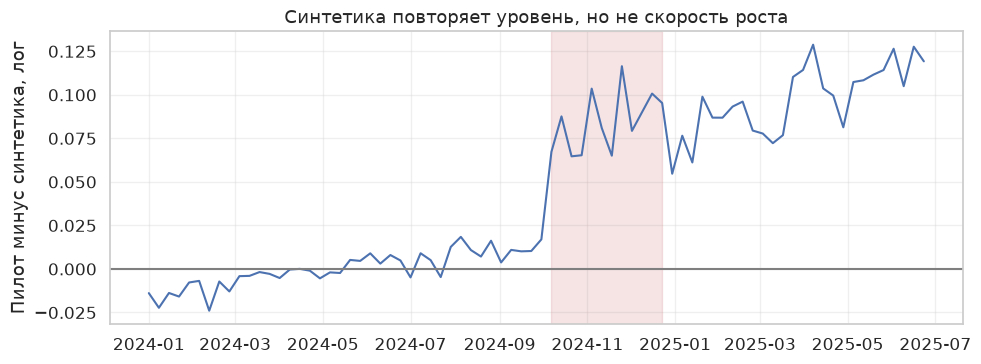

In [18]:
def synth_effect(matrix, treated, candidates, t0, post=POST):
    target = matrix[:t0, treated].mean(axis=1)
    A = np.r_[matrix[:t0, candidates], 100 * np.ones((1, len(candidates)))]
    w = nnls(A, np.r_[target, 100])[0]
    w = w / w.sum()
    synth = matrix[:, candidates] @ w
    gap_synth = matrix[:, treated].mean(axis=1) - synth
    return gap_synth, gap_synth[t0:t0 + post].mean() - gap_synth[t0 - PRE:t0].mean(), (w > 1e-3).sum()


gap_synth, sc_effect, n_donors = synth_effect(Y, pilot_idx, rest_idx, T0)
sc_placebo = [synth_effect(Y, pilot_idx, rest_idx, t)[1] for t in PLACEBO_T0]
print(f"Синтетический контроль: {np.expm1(sc_effect):+.2%}, доноров с весом: {n_donors}")
print('Плацебо: ' + ', '.join(f"{np.expm1(v):+.2%}" for v in sc_placebo))
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(WEEKS, gap_synth, color=BLUE)
ax.axvspan(WEEKS[T0], WEEKS[T0 + POST - 1], color=RED, alpha=0.15)
ax.axhline(0, color=GRAY); ax.set_ylabel('Пилот минус синтетика, лог')
ax.set_title('Синтетика повторяет уровень, но не скорость роста')
plt.show()

### Вторая волна: если бы рандомизировали

Директор согласился на вторую волну: 60 магазинов, **случайно внутри пар**. Оценим на истории до пилота разброс четырёх дизайнов для 30 + 30 магазинов: только пилот (разность средних за 12 недель), пары по уровню, DiD, пары + DiD. Пары строим по уровню до старта внутри формата, знак в паре выбираем монеткой.

In [19]:
def design_spread(k: int = 30, R: int = 400, seed: int = SEED) -> pd.Series:
    rng = np.random.default_rng(seed)
    fmt_groups = info['format'].to_numpy()
    out = {name: [] for name in ('Только пилот', 'Пары по уровню', 'DiD', 'Пары + DiD')}
    for _ in range(R):
        t0 = random_window(rng)
        idx = rng.choice(N_STORES, 2 * k, replace=False)
        after, before = HIST[t0:t0 + POST].mean(axis=0), HIST[t0 - PRE:t0].mean(axis=0)
        delta = after - before
        t, c = idx[:k], idx[k:]
        out['Только пилот'].append(after[t].mean() - after[c].mean())
        out['DiD'].append(delta[t].mean() - delta[c].mean())
        first = idx[:k]
        second = match_controls(before, first, idx[k:], fmt_groups)
        signs = rng.choice([-1, 1], k)
        out['Пары по уровню'].append((signs * (after[first] - after[second])).mean())
        out['Пары + DiD'].append((signs * (delta[first] - delta[second])).mean())
    return 100 * pd.Series({name: np.std(v) for name, v in out.items()})


spread = design_spread()
spread.round(2).to_frame('Разброс оценки, %')

,"Разброс оценки, %"
Только пилот,9.57
Пары по уровню,6.14
DiD,0.55
Пары + DiD,0.52


Картина та же, что на симуляции в разделе 2. Основное снижение разброса даёт учёт предпериода (DiD): магазины различаются уровнем намного сильнее, чем меняются во времени (ICC 0.94). Пары поверх DiD добавляют мало, зато страхуют от неудачного разбиения при малом числе магазинов и дают понятный бизнесу анализ «каждому пилотному — свой контрольный». И главное: при случайном знаке в паре смещения от отбора нет вообще.

**Вопрос.** В пилоте директора 63% магазинов формата «a», а в сети — 48%. Если эффект зоны зависит от формата, как перенести оценку на всю сеть и что для этого заложить в дизайн второй волны?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Среднее по пилоту — это эффект для структуры пилота, а не сети. Перевзвешивание (пост-стратификация): оценить эффект отдельно по каждому формату и сложить с весами сети (48% / 37% / 15%), а не пилота (63% / 35% / 2%).

Здесь это упирается в данные: формата «c» в пилоте один магазин, оценки для него нет, и никакое перевзвешивание её не создаст — только допущение «как у соседних форматов».

Во второй волне: стратифицировать по формату (пары внутри формата уже это делают), набрать в каждый формат достаточно магазинов по MDE из раздела 2 и заранее решить, принимаем ли решение по сети в целом или по форматам.

</details>

## 6. Интерференция и switchback

Другая гипотеза сети — про доставку из магазинов. SUTVA требует, чтобы исход единицы зависел только от её собственного назначения: $Y_i(Z_1, ..., Z_n) = Y_i(Z_i)$. На двусторонних рынках это неверно: тестовые заказы и контрольные делят **общий ресурс** — курьеров, водителей, товарный остаток. Тест забирает ресурс у контроля, и A/B видит разницу, которой при полном внедрении не будет. Это не шум, а **смещение**: оно не уменьшается от роста выборки.

Симуляция: зона в течение часа, 200 клиентов, курьеров — случайное число около заданного уровня. Новая механика повышает долю клиентов, готовых заказать, с 60% до 72%. Заказов больше, чем курьеров, — лишние не выполняются, а выполненные делятся между группами случайно.

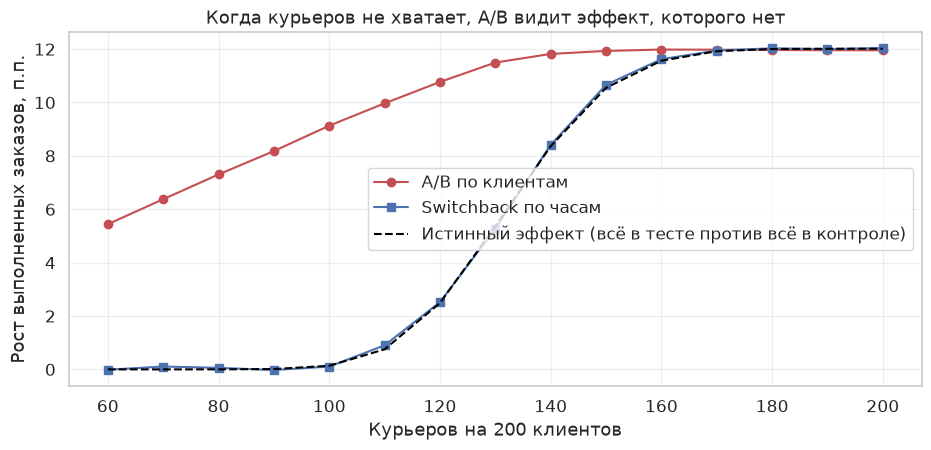

,Истинный эффект,A/B по клиентам,Switchback по часам
80,0.0,7.3,0.1
120,2.5,10.8,2.5
160,11.6,12.0,11.6
200,12.0,12.0,12.0


In [20]:
def market_hour(n_clients, n_test, couriers, rng, p_control=0.60, p_test=0.72):
    demand_test = rng.binomial(n_test, p_test)
    demand_control = rng.binomial(n_clients - n_test, p_control)
    done = np.minimum(demand_test + demand_control, couriers)
    done_test = rng.hypergeometric(demand_test, demand_control, done)
    return done_test, done - done_test


def interference(supply, hours=20_000, n=200, seed=1):
    rng = np.random.default_rng(seed)
    clients, couriers = np.full(hours, n), rng.poisson(supply, hours)
    all_test, _ = market_hour(clients, clients, couriers, rng)
    _, all_control = market_hour(clients, np.zeros(hours, int), couriers, rng)
    half = np.full(hours, n // 2)
    t, c = market_hour(clients, half, couriers, rng)
    switch = rng.integers(0, 2, hours).astype(bool)
    st, sc = market_hour(clients, switch * n, couriers, rng)
    total = st + sc
    return {'Истинный эффект': (all_test.mean() - all_control.mean()) / n,
            'A/B по клиентам': (t.mean() - c.mean()) / (n // 2),
            'Switchback по часам': (total[switch].mean() - total[~switch].mean()) / n}


supply_grid = np.arange(60, 201, 10)
curves = pd.DataFrame([interference(s) for s in supply_grid], index=supply_grid)
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(curves.index, 100 * curves['A/B по клиентам'], 'o-', color=RED, label='A/B по клиентам')
ax.plot(curves.index, 100 * curves['Switchback по часам'], 's-', color=BLUE, label='Switchback по часам')
ax.plot(curves.index, 100 * curves['Истинный эффект'], '--', color='black', label='Истинный эффект (всё в тесте против всё в контроле)')
ax.set(xlabel='Курьеров на 200 клиентов', ylabel='Рост выполненных заказов, п.п.',
       title='Когда курьеров не хватает, A/B видит эффект, которого нет')
ax.legend(); plt.show()
(100 * curves.loc[[80, 120, 160, 200]]).round(1)

При 80 курьерах на 200 клиентов истинный эффект равен нулю: всё упирается в курьеров. A/B показывает **+7.3 п.п.**: тест просто забирает курьеров у контроля. При 120 курьерах истина 2.5 п.п., A/B — 10.8. Switchback попадает в истину (0.1 и 2.5). При 160 курьерах разрыв почти исчез (11.6 против 12.0), при 200 методы совпадают: курьеров хватает всем.

**Switchback** рандомизирует не клиента, а **зону × окно времени**: всё окно целиком в тесте или в контроле. Внутри окна интерференции между группами нет. Цена — два новых вопроса.

* **Carryover.** После переключения система не сразу приходит в новый режим: курьеры перераспределяются, очередь заказов рассасывается. Если перенос длится $m$ часов, а окно — $w$, то без отбрасывания первые часы окна смешивают режимы. При случайном переключении (вероятность смены 1/2) смещение примерно $-\tau m / (2w)$ ($\tau$ — полный эффект нового режима) при $w \ge m$: окно 3 часа при $m = 2$ теряет треть эффекта.
* **Окно.** Короткое окно — много рандомизаций и маленькая дисперсия, но большая доля переходных часов (смещение). Длинное — перенос пренебрежим, но независимых окон мало, и дисперсия растёт.
* **Анализ.** Единица — эпоха (зона × окно), а не заказ и не час. Проверка — A/A по эпохам, как ниже.

**Вопрос.** Перенос — 2 часа. Какое окно взять: 1 час, чтобы рандомизаций было как можно больше, или сутки, чтобы перенос не мешал?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Ни то, ни другое.

* **1 час без отбрасывания** в расчёте ниже почти целиком состоит из переходного режима и теряет две трети эффекта (−0.67 при эффекте 1.0).
* **Сутки** почти без смещения, но эпох мало, а соседние часы похожи: разброс 0.156 против 0.065 у окна 3 часа.

Рабочий рецепт: отбрасывать первые 2 часа каждого окна (burn-in) и брать окно в несколько длительностей переноса. Минимум RMSE здесь при 3 часах. Но перенос известен неточно: если на деле он 3 часа, окно 3 часа с burn-in 2 часа уже смещено. Поэтому окно берут с запасом, около трёх длительностей переноса — 6 часов: в нём есть место отбросить и 3 часа, если перенос окажется длиннее. Цена — RMSE 0.095 против 0.065 (при burn-in 2 часа).

</details>

In [21]:
m_carry, tau = 2, 1.0
w = np.array([2, 3, 4, 6, 8, 12, 24])
print(pd.DataFrame({'Окно w, ч': w, 'Смещение без burn-in ≈ −τ·m/(2w), w ≥ m': (-tau * m_carry / (2 * w)).round(3),
                    'Доля данных, которую съедает burn-in m/w': (m_carry / w).round(2)}).to_string(index=False))

 Окно w, ч  Смещение без burn-in ≈ −τ·m/(2w), w ≥ m  Доля данных, которую съедает burn-in m/w
         2                                   -0.500                                      1.00
         3                                   -0.333                                      0.67
         4                                   -0.250                                      0.50
         6                                   -0.167                                      0.33
         8                                   -0.125                                      0.25
        12                                   -0.083                                      0.17
        24                                   -0.042                                      0.08


### Окно и A/A по эпохам

Новый алгоритм назначения курьеров. Курьеры в зоне общие, поэтому рандомизируем **зону × окно времени**.

Симулятор: 20 зон, 4 недели почасовых данных, у зон разный уровень, есть суточный цикл, шум автокоррелирован (AR 0.9: соседние часы похожи). Эффект +1.0 заказа в час, но набирается не сразу: курьерам нужно **2 часа**, чтобы перераспределиться (carryover). После переключения первые 2 часа окна — смесь режимов.

In [22]:
N_ZONES, N_HOURS, SB_EFFECT, CARRYOVER = 20, 24 * 28, 1.0, 2


def make_schedule(window: int, rng, n_zones: int = N_ZONES, n_hours: int = N_HOURS) -> np.ndarray:
    # Зона × час: внутри окна длиной window режим не меняется
    return np.repeat(rng.integers(0, 2, size=(n_zones, n_hours // window)), window, axis=1)


def simulate_zones(schedule: np.ndarray, effect: float, rng, carryover: int = CARRYOVER, ar: float = 0.9) -> np.ndarray:
    n_zones, n_hours = schedule.shape
    daily = 4 * np.sin(2 * np.pi * np.arange(n_hours) / 24)
    level = rng.normal(0, 3, (n_zones, 1))
    shocks = rng.normal(0, 1, (n_zones, n_hours))
    shocks[:, 0] /= np.sqrt(1 - ar ** 2)
    noise = lfilter([1], [1, -ar], shocks, axis=1)
    exposure = lfilter(np.ones(carryover + 1) / (carryover + 1), [1], schedule.astype(float), axis=1)
    return 20 + level + daily + noise + effect * exposure

Оценка по эпохам:

1. вычитаем суточный цикл — среднее по всем зонам и дням для каждого часа суток;
2. режем ряд каждой зоны на окна длиной `window`, **отбрасываем первые `burn` часов** каждого окна, усредняем остаток — это значение эпохи;
3. в каждой зоне: среднее тестовых эпох минус среднее контрольных; зоны, где нет одной из групп, пропускаем;
4. эффект — среднее этих разностей по зонам, тест — одновыборочный t-тест по зонам.

Зона сама себе контроль, поэтому её уровень сокращается.

In [23]:
def switchback_estimate(outcome: np.ndarray, schedule: np.ndarray, window: int, burn: int = 0) -> tuple:
    n_zones, n_hours = outcome.shape
    hour_of_day = outcome.reshape(n_zones, -1, 24).mean(axis=(0, 1))
    y = outcome - np.tile(hour_of_day, n_hours // 24)
    epochs = y.reshape(n_zones, n_hours // window, window)[:, :, burn:].mean(axis=2)
    arm = schedule[:, ::window]
    with np.errstate(invalid='ignore', divide='ignore'):
        diff = (epochs * arm).sum(axis=1) / arm.sum(axis=1) - (epochs * (1 - arm)).sum(axis=1) / (1 - arm).sum(axis=1)
    d = diff[np.isfinite(diff)]
    return d.mean(), d.std(ddof=1) / np.sqrt(len(d)), stats.ttest_1samp(d, 0).pvalue

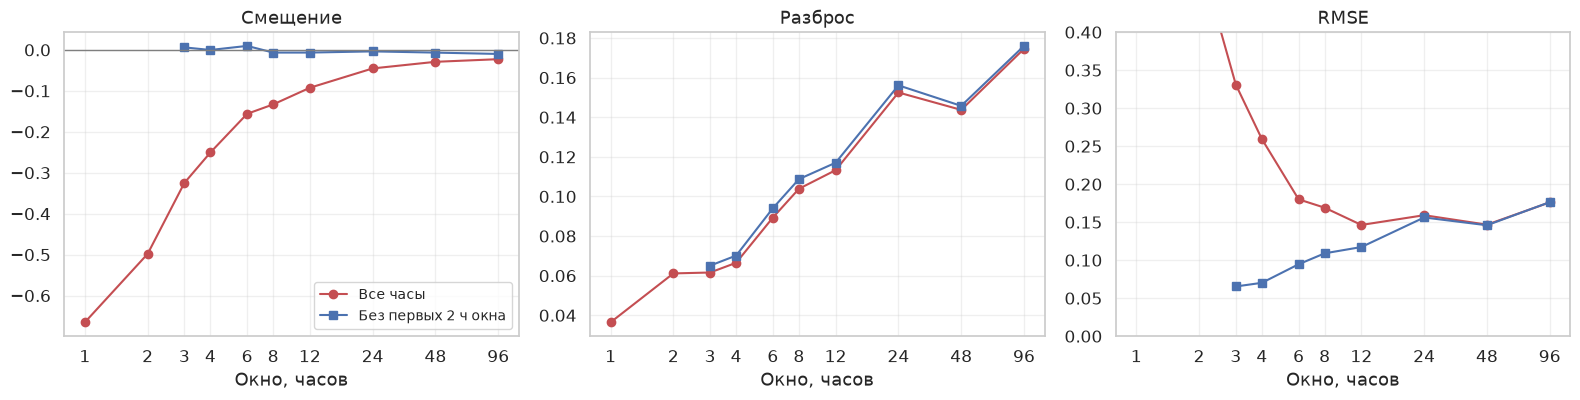

Лучшее окно по RMSE (с отбрасыванием 2 ч): 3 ч


Смещение        Разброс          RMSE       
Отбрасываем, ч        0      2       0      2      0      2
Окно, ч                                                    
1                -0.665    NaN   0.036    NaN  0.666    NaN
2                -0.498    NaN   0.061    NaN  0.502    NaN
3                -0.325  0.006   0.062  0.065  0.331  0.065
4                -0.251 -0.000   0.066  0.070  0.259  0.070
6                -0.156  0.010   0.089  0.094  0.180  0.095
8                -0.133 -0.007   0.104  0.109  0.169  0.109
12               -0.093 -0.007   0.113  0.117  0.146  0.117
24               -0.045 -0.004   0.152  0.156  0.159  0.156
48               -0.029 -0.007   0.144  0.146  0.147  0.146
96               -0.023 -0.010   0.174  0.176  0.176  0.176

In [24]:
WINDOWS = [1, 2, 3, 4, 6, 8, 12, 24, 48, 96]


def window_study(R: int = 120, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    rows = []
    for window in WINDOWS:
        estimates = {0: [], CARRYOVER: []}
        for _ in range(R):
            schedule = make_schedule(window, rng)
            outcome = simulate_zones(schedule, SB_EFFECT, rng)
            for burn in estimates:
                if burn < window:
                    estimates[burn].append(switchback_estimate(outcome, schedule, window, burn)[0])
        for burn, values in estimates.items():
            if values:
                v = np.array(values)
                rows.append({'Окно, ч': window, 'Отбрасываем, ч': burn, 'Смещение': v.mean() - SB_EFFECT,
                             'Разброс': v.std(), 'RMSE': np.sqrt(((v - SB_EFFECT) ** 2).mean())})
    return pd.DataFrame(rows)


study = window_study()
burned = study[study['Отбрасываем, ч'] == CARRYOVER].set_index('Окно, ч')
raw = study[study['Отбрасываем, ч'] == 0].set_index('Окно, ч')
best_window = int(burned['RMSE'].idxmin())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, metric in zip(axes, ['Смещение', 'Разброс', 'RMSE']):
    ax.plot(raw.index, raw[metric], 'o-', color=RED, label='Все часы')
    ax.plot(burned.index, burned[metric], 's-', color=BLUE, label=f'Без первых {CARRYOVER} ч окна')
    ax.set_xscale('log', base=2); ax.set_xticks(WINDOWS, WINDOWS); ax.minorticks_off()
    ax.set_xlabel('Окно, часов'); ax.set_title(metric)
axes[0].axhline(0, color=GRAY, linewidth=1); axes[0].legend(fontsize=10)
axes[2].set_ylim(0, 0.4)
plt.tight_layout(); plt.show()
print(f"Лучшее окно по RMSE (с отбрасыванием {CARRYOVER} ч): {best_window} ч")
study.pivot(index='Окно, ч', columns='Отбрасываем, ч', values=['Смещение', 'Разброс', 'RMSE']).round(3)

* **Без отбрасывания короткие окна занижают эффект.** Окно 1 час теряет две трети эффекта (−0.67), окно 3 часа — треть (−0.33). Это формула $-\tau m / (2w)$, верная при $w \ge m$. Окно 1 час короче переноса, формула для него дала бы −1.0, а на деле −0.67.
* **Отбрасывание первых 2 часов окна** убирает смещение при любом окне от 3 часов. Остаётся разброс, и он растёт с окном: 0.065 при 3 часах, 0.18 при 96 часах. Эпох становится меньше, а соседние часы похожи.
* **Минимум RMSE — окно 3 часа (0.065),** при 4 часах почти столько же (0.070), при 6 часах — 0.095.

Осталось проверить анализ на A/A: обычный t-тест по зона-часам против теста по эпохам.

**Вопрос.** Как будет вести себя t-тест по зона-часам на A/A при разных окнах? Почему?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Он ошибается тем сильнее, чем длиннее окно, хотя данных столько же: в расчёте ниже 4% при окне 1 час и 24–66% при окнах 3–24 часа.

Часы внутри окна получают одно и то же назначение и похожи между собой (AR-шум, уровень зоны). Окно — это кластер из $w$ часов, и его дизайн-эффект $1 + (w-1)\rho$ растёт с длиной окна $w$. При окне 1 час кластер — один час, и наивный тест почти честен. Дальше независимых назначений всё меньше, а t-тест по часам продолжает считать их тысячами. Тест по эпохам знает, сколько на самом деле было рандомизаций, и держит около 5%.

</details>

In [25]:
def sb_aa(windows=(1, 3, 6, 12, 24), R: int = 200, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)
    out = {}
    for window in windows:
        hourly, epoch = [], []
        for _ in range(R):
            schedule = make_schedule(window, rng)
            outcome = simulate_zones(schedule, 0.0, rng)
            hourly.append(stats.ttest_ind(outcome[schedule == 1], outcome[schedule == 0]).pvalue < ALPHA)
            epoch.append(switchback_estimate(outcome, schedule, window)[2] < ALPHA)
        out[window] = {'t-тест по зона-часам': np.mean(hourly), 'Тест по эпохам': np.mean(epoch)}
    return pd.DataFrame(out).T.rename_axis('Окно, ч')


aa_sb = sb_aa()
aa_sb.round(3)

,t-тест по зона-часам,Тест по эпохам
"Окно, ч",,
1,0.040,0.025
3,0.240,0.050
6,0.445,0.055
12,0.485,0.060
24,0.655,0.080


t-тест по зона-часам срабатывает в 24–66% случаев при окнах 3–24 часа. Тест по эпохам держит 2.5–8% (200 прогонов, шум ±3 п.п.).

## 7. Итог: карта «ограничение → дизайн»

| Ограничение | Что ломается | Дизайн | Проверка |
| --- | --- | --- | --- |
| Воздействие на магазин/регион/класс | независимость наблюдений | кластерный A/B, анализ по кластерам | A/A на истории, ICC и DE |
| Мало единиц, они разные | мощность | пары + DiD, мощность инъекцией | MDE по истории, A/A |
| Список выбрал бизнес | случайность назначения | DiD с матчингом и поправкой на тренд; следующая волна — монетка внутри пар | плацебо по датам на всём конвейере, стресс-тест тренда |
| Общий ресурс (курьеры, склад) | SUTVA | switchback, кластеры на графе | carryover, окно, A/A по эпохам |
| Рандомизация невозможна | всё сразу | geo-эксперимент, синтетический контроль | плацебо по датам и донорам, пилот внутри облака доноров по динамике |

Что получилось на кейсе сети:

* **Единица.** ICC 0.94: 12 недель магазина весят как одно наблюдение, а t-тест по магазино-неделям ошибается на A/A в 58% случаев. Тест — по магазинам.
* **Мощность.** MDE считаем инъекцией по истории. Его покупают магазины, а не недели. У пилота директора MDE 0.85%, так что дело не в шуме.
* **Смещение.** Наивный DiD даёт +5.8%, плацебо до старта — +2.3%. Пары по уровню этого не лечат (+5.9%). Поправка на тренд даёт +3.6%, плацебо около нуля, истина — +3.53%. По правилу, зафиксированному до просмотра оценки, — не раскатывать: 3.6% против порога 4.5%, запас 0.9 п.п. держится на допущении о линейном тренде.
* **Switchback.** При переносе 2 часа отбрасываем начало каждого окна. Минимум RMSE при окне 3 часа; с запасом на неточный перенос — 6 часов. Тест — по эпохам.

Артефакт встречи — карта `design_map.md` в папке встречи: таблица «ограничение → дизайн → что проверить → ловушка». Строки 1, 3, 4, 6, 7 и 8 карты уже содержат числа этого кейса; пустую строку 12 заполните своими примерами из практики команды.